# Лабораторная работа 6. Градиентный бустинг

**Вариант:** 7 (нечётный → градиентный бустинг)

Датасет — `StudentPerformanceFactors.csv` из лабораторной 2 (разведочный анализ): факторы, влияющие на успеваемость студентов. Целевой признак `Exam_Score` — итоговый балл за экзамен (число), поэтому это задача **регрессии**: качество оцениваем метриками MSE, RMSE и R².

> **Подсказка: что такое градиентный бустинг.**
> Модель — это **сумма** многих маленьких (неглубоких) деревьев решений, которые строятся **по очереди**. Первое дерево грубо предсказывает ответ. Каждое следующее дерево обучается не на самом ответе, а на **ошибках** (остатках) уже построенной суммы и «подправляет» её. Итог: F(x) = F₀ + η·T₁(x) + η·T₂(x) + … + η·Tₘ(x).
> - `n_estimators` — число деревьев (шагов исправления ошибок).
> - `learning_rate` (η) — насколько сильно каждое дерево влияет на итог. Маленький η требует больше деревьев, но обычно обобщает лучше.
> - `max_depth` — глубина каждого дерева (в бустинге берут неглубокие, 2–5).
> - `subsample` — доля объектов, на которой строится каждое дерево (если меньше 1, бустинг стохастический, это снижает переобучение).
> - «Градиентный» потому, что остатки — это антиградиент функции потерь (для MSE именно разность «правда − предсказание»), то есть каждое дерево делает шаг градиентного спуска, как в лабе 3, но в пространстве функций.

### Задание 1
Подготовить и проанализировать набор данных: очистка и предобработка (пропуски, масштабирование, кодирование категориальных признаков).

In [1]:
import numpy as np                                    # массивы и математика
import pandas as pd                                   # таблицы
import matplotlib.pyplot as plt                       # графики
import seaborn as sns                                 # красивые графики поверх matplotlib
from sklearn.ensemble import GradientBoostingRegressor  # градиентный бустинг для регрессии
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score  # разбиение, подбор параметров, кросс-валидация
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # метрики регрессии
from sklearn.preprocessing import StandardScaler      # стандартизация

RANDOM_STATE = 42                                     # зерно случайности для воспроизводимости
pd.set_option('display.max_columns', None)            # показывать все столбцы таблиц

df = pd.read_csv('data/StudentPerformanceFactors.csv')  # читаем данные
print('Размер (строк, столбцов):', df.shape)          # сколько студентов и признаков
df.head()                                             # первые строки

Размер (строк, столбцов): (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
df.info()                                             # типы столбцов и число непустых значений

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [3]:
df.describe().T.round(2)                              # статистика по числовым столбцам

,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.98,5.99,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.98,11.55,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.03,1.47,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.07,14.40,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.49,1.23,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.97,1.03,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.24,3.89,55.0,65.0,67.0,69.0,101.0


**1.1 Целевая переменная и пропуски.**

Пропуски по столбцам (только где есть):
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64
Дубликатов: 0


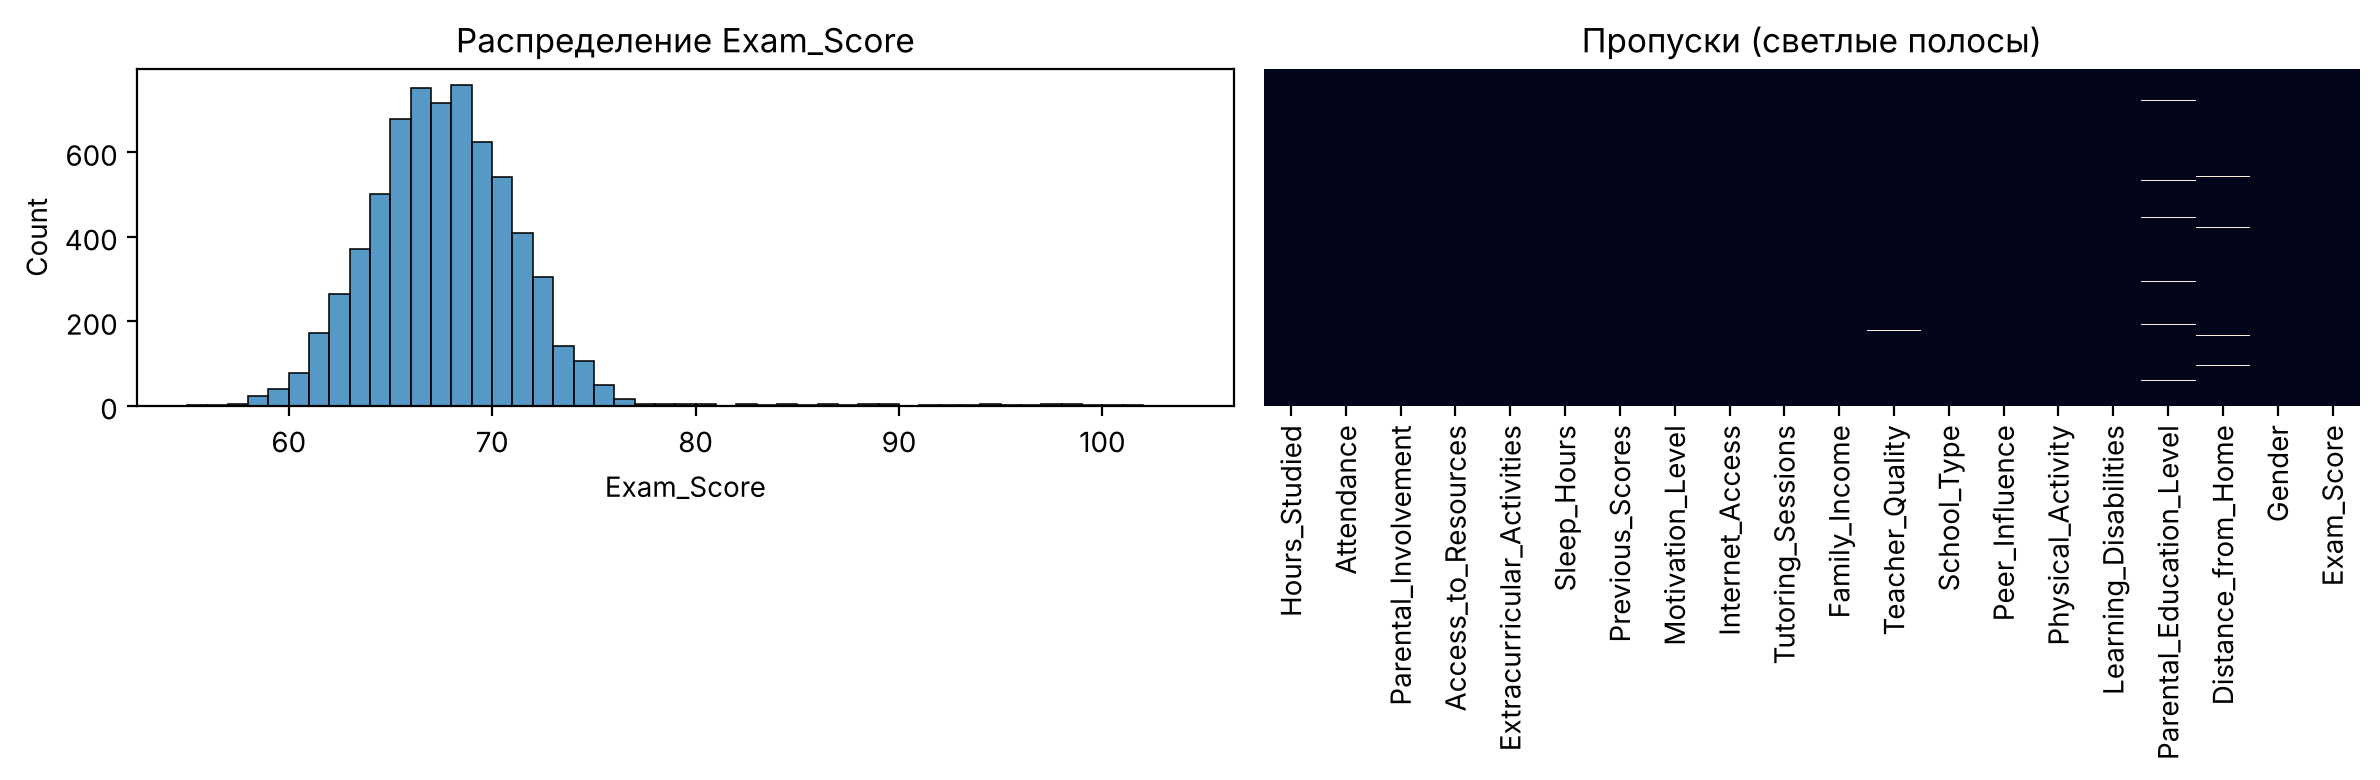

In [4]:
print('Пропуски по столбцам (только где есть):')
print(df.isna().sum()[lambda s: s > 0])               # три категориальных столбца имеют пропуски
print('Дубликатов:', df.duplicated().sum())           # полные дубликаты строк

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Exam_Score'], bins=range(55, 105), ax=axes[0])   # распределение целевой переменной
axes[0].set_title('Распределение Exam_Score')
sns.heatmap(df.isna(), cbar=False, yticklabels=False, ax=axes[1]) # тепловая карта пропусков
axes[1].set_title('Пропуски (светлые полосы)')
plt.tight_layout(); plt.show()

Пропуски только в трёх категориальных признаках (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`), их доля мала (около 1%), поэтому заполняем **модой** (самым частым значением), как и в лабораторной 2. В целевой переменной есть значение 101, а экзаменационный балл не может превышать 100 — это ошибка данных, такую строку удаляем.

In [5]:
for col in ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']:
    df[col] = df[col].fillna(df[col].mode()[0])       # заполняем пропуски самым частым значением

print('Недопустимых значений Exam_Score (>100):', (df['Exam_Score'] > 100).sum())
df = df[df['Exam_Score'] <= 100].reset_index(drop=True)  # убираем строку с невозможным баллом
print('Пропусков осталось:', df.isna().sum().sum(), ' Размер:', df.shape)

Недопустимых значений Exam_Score (>100): 1
Пропусков осталось: 0  Размер: (6606, 20)


**1.2 Выбросы.** Проверим числовые признаки по правилу IQR. Деревья решений (а значит, и бустинг) устойчивы к выбросам, потому что сравнивают значения с порогами, и величина «хвоста» не важна. Поэтому ограничиваемся мягкой мерой: подрезаем (clip) выбросы по границам IQR, не удаляя строки.

In [6]:
num_cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1       # квартили и межквартильный размах
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr                   # границы IQR
    rows.append({'признак': col, 'нижняя': low, 'верхняя': high,
                 'выбросов': int(((df[col] < low) | (df[col] > high)).sum())})
outliers = pd.DataFrame(rows); outliers

,признак,нижняя,верхняя,выбросов
0,Hours_Studied,4.0,36.0,43
1,Attendance,40.0,120.0,0
2,Sleep_Hours,3.0,11.0,0
3,Previous_Scores,25.5,125.5,0
4,Tutoring_Sessions,-0.5,3.5,429
5,Physical_Activity,-1.0,7.0,0


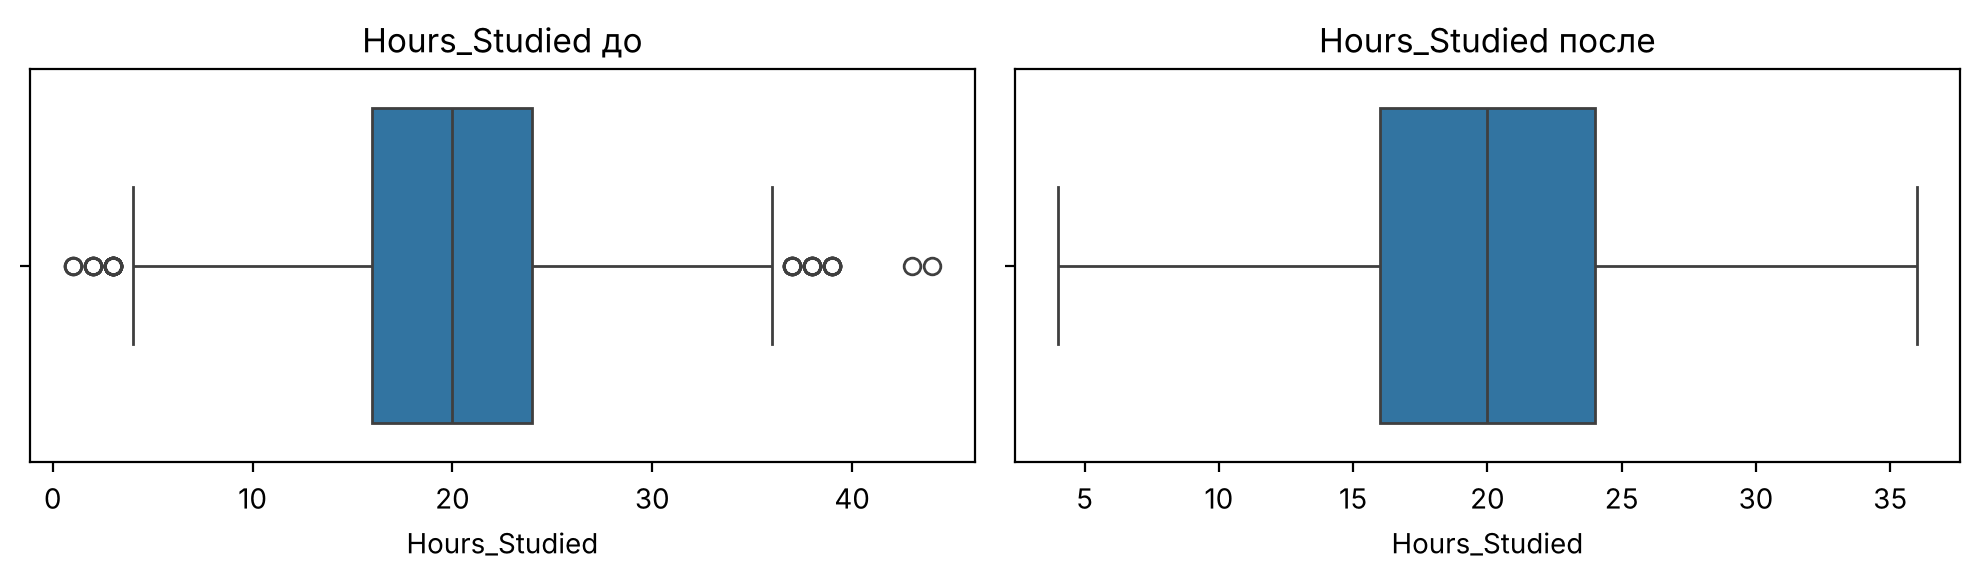

In [7]:
low, high = 4.0, 36.0                                 # границы IQR для Hours_Studied (из таблицы выше)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(x=df['Hours_Studied'], ax=axes[0]); axes[0].set_title('Hours_Studied до')
df['Hours_Studied'] = df['Hours_Studied'].clip(low, high)        # подрезаем выбросы до границ
sns.boxplot(x=df['Hours_Studied'], ax=axes[1]); axes[1].set_title('Hours_Studied после')
plt.tight_layout(); plt.show()

Выбросы по IQR есть у `Hours_Studied` (43 значения, около 0.7%) и у `Tutoring_Sessions` (429 значений, около 6.5%); остальные признаки в допустимых границах. `Hours_Studied` подрезали. `Tutoring_Sessions` — это счётчик занятий с репетитором (целые 0–8): значения 4–8 встречаются нередко и являются реальными данными, а не ошибками, поэтому их оставляем (деревьям они не мешают).

**1.3 Кодирование категориальных признаков.** Модель работает с числами, поэтому категории нужно закодировать:
- у признаков с естественным порядком (Low < Medium < High и т. п.) используем **порядковое кодирование** (0, 1, 2), оно сохраняет порядок и не раздувает число столбцов;
- бинарные признаки (Yes/No, Male/Female, Public/Private) кодируем 0/1.

One-hot кодирование здесь не нужно: номинальных признаков с более чем двумя значениями нет.

In [8]:
level = {'Low': 0, 'Medium': 1, 'High': 2}                        # порядок для уровней
for col in ['Parental_Involvement', 'Access_to_Resources', 'Motivation_Level', 'Family_Income', 'Teacher_Quality']:
    df[col] = df[col].map(level)
df['Peer_Influence'] = df['Peer_Influence'].map({'Negative': 0, 'Neutral': 1, 'Positive': 2})
df['Parental_Education_Level'] = df['Parental_Education_Level'].map({'High School': 0, 'College': 1, 'Postgraduate': 2})
df['Distance_from_Home'] = df['Distance_from_Home'].map({'Near': 0, 'Moderate': 1, 'Far': 2})
for col in ['Extracurricular_Activities', 'Internet_Access', 'Learning_Disabilities']:
    df[col] = df[col].map({'No': 0, 'Yes': 1})
df['School_Type'] = df['School_Type'].map({'Public': 0, 'Private': 1})
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

print('Пропусков после кодирования:', df.isna().sum().sum())   # убеждаемся, что все значения распознаны
print('Типы столбцов:', df.dtypes.unique())                     # теперь все числовые
df.head()

Пропусков после кодирования: 0
Типы столбцов: [dtype('int64')]


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,0,2,0,7,73,0,1,0,0,1,0,2,3,0,0,0,0,67
1,19,64,0,1,0,8,59,0,1,2,1,1,0,0,4,0,1,1,1,61
2,24,98,1,1,1,7,91,1,1,2,1,1,0,1,4,0,2,0,0,74
3,29,89,0,1,1,8,98,1,1,1,1,1,0,0,4,0,0,1,0,71
4,19,92,1,1,1,6,65,1,1,3,1,2,0,1,4,0,1,0,1,70


**1.4 Анализ связи с целевой переменной и разбиение.**

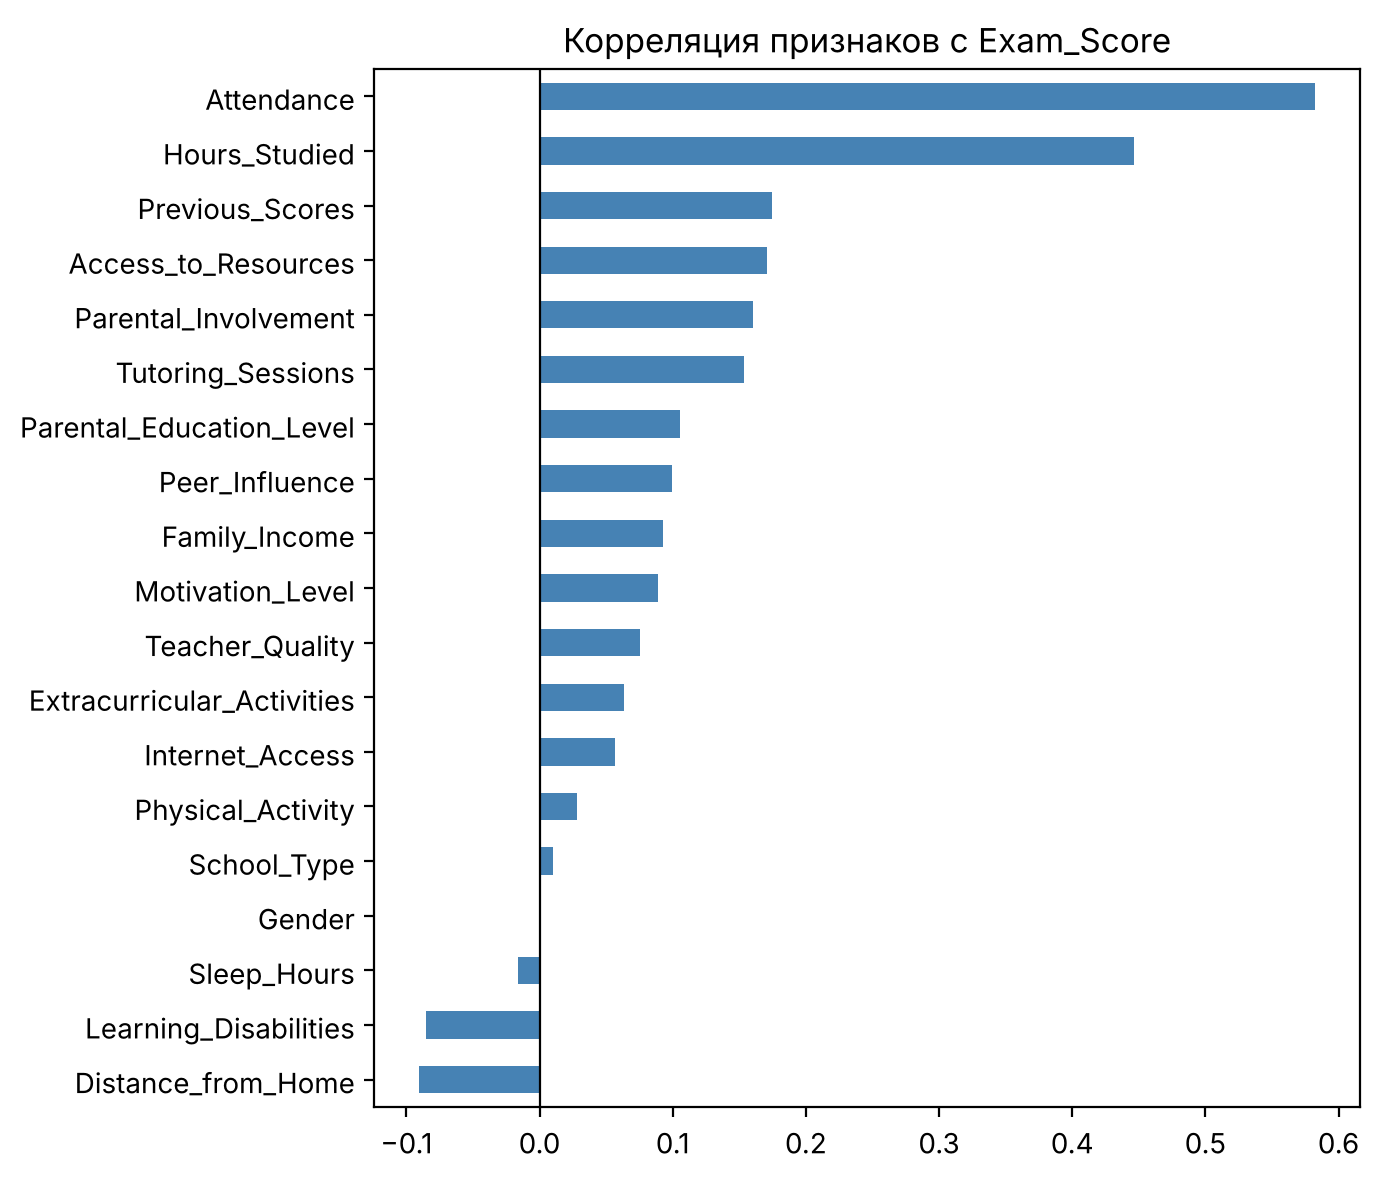

Parental_Involvement    0.160
Access_to_Resources     0.171
Previous_Scores         0.174
Hours_Studied           0.446
Attendance              0.582
Name: Exam_Score, dtype: float64


In [9]:
corr = df.corr()['Exam_Score'].drop('Exam_Score').sort_values()   # корреляция каждого признака с баллом
plt.figure(figsize=(7, 6))
corr.plot(kind='barh', color='steelblue')
plt.title('Корреляция признаков с Exam_Score'); plt.axvline(0, color='k', lw=0.8)
plt.tight_layout(); plt.show()
print(corr.round(3).tail(5))                                       # самые связанные признаки

In [10]:
X = df.drop(columns='Exam_Score')                     # признаки
y = df['Exam_Score']                                  # цель
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE    # 80% на обучение, 20% на тест
)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Доля баллов >= 80: train %.4f, test %.4f' % ((y_train >= 80).mean(), (y_test >= 80).mean()))

Train: (5284, 19)  Test: (1322, 19)
Доля баллов >= 80: train 0.0079, test 0.0038


**1.5 Нужно ли масштабирование?** Для деревьев (а значит, и для бустинга) масштаб признаков не важен: каждый узел сравнивает один признак с порогом, и монотонное преобразование не меняет порядок объектов. Проверим это: обучим бустинг на исходных и на стандартизованных признаках и сравним ошибку.

In [11]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)             # скейлер учим только на train
X_test_s = scaler.transform(X_test)                   # к тесту применяем те же параметры

m_raw = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(X_train, y_train)
m_scaled = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(X_train_s, y_train)
print('RMSE без масштабирования:', round(mean_squared_error(y_test, m_raw.predict(X_test)) ** 0.5, 4))
print('RMSE со стандартизацией: ', round(mean_squared_error(y_test, m_scaled.predict(X_test_s)) ** 0.5, 4))

RMSE без масштабирования: 1.6959
RMSE со стандартизацией:  1.6959


**Итог по заданию 1.**
- **Пропуски:** 235 значений в трёх категориальных признаках заполнены модой (самым частым значением).
- **Некорректные данные:** удалена одна строка с баллом 101 (больше максимума 100), осталось 6606 студентов.
- **Выбросы:** у `Hours_Studied` 43 значения подрезаны по границам IQR; у `Tutoring_Sessions` выбросы по IQR оставлены, так как это реальные данные.
- **Кодирование:** 13 категориальных признаков превращены в числа (8 порядковых и 5 бинарных), теперь все признаки числовые.
- **Масштабирование не требуется:** бустинг построен на деревьях, и RMSE на исходных и стандартизованных признаках одинаков (1.6959).
- **Связи с целью:** сильнее всего с баллом коррелируют `Attendance` (r = 0.58) и `Hours_Studied` (r = 0.45).
- **Разбиение:** 5284 объекта в train и 1322 в test.

Важная деталь для дальнейших выводов: в тест случайно попало вдвое меньше очень высоких баллов (≥ 80), чем в обучающую часть (0.38% против 0.79%).

### Задание 2
Обучить модель градиентного бустинга на выбранных данных с исходными (стандартными) параметрами, обучить на тренировочной части, сделать прогнозы на тестовой части.

(В тексте задания написано «создать модель случайного леса», но по названию раздела и варианту речь о градиентном бустинге; используем `GradientBoostingRegressor`.)

In [12]:
base_model = GradientBoostingRegressor(random_state=RANDOM_STATE)  # параметры по умолчанию
print(base_model.get_params())                        # показываем исходные параметры

base_model.fit(X_train, y_train)                      # обучение на тренировочной части
y_pred_base = base_model.predict(X_test)              # прогнозы на тестовой части

pd.DataFrame({'факт': y_test.values[:10], 'прогноз': y_pred_base[:10].round(1)})  # первые 10 примеров

{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.1, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


,факт,прогноз
0,66,67.1
1,66,65.1
2,67,68.0
3,67,67.4
4,68,67.6
5,63,62.3
6,74,73.8
7,65,64.5
8,69,68.5
9,76,74.4


**Итог по заданию 2.** Модель по умолчанию — это 100 деревьев глубиной 3 со скоростью обучения 0.1 и без подвыборки. Она обучена на train, а прогнозы на тесте для первых десяти студентов отличаются от фактических баллов в пределах 1–2 баллов.

### Задание 3
Оценить качество модели метриками. Метрики accuracy, precision, recall и F1 относятся к классификации, а у нас регрессия, поэтому считаем **MSE**, **RMSE** и **R²** (и дополнительно MAE).

- **MSE** — средний квадрат ошибки (в баллах²); **RMSE** — корень из MSE, ошибка в тех же единицах, что и балл;
- **R²** — доля дисперсии целевой переменной, объяснённая моделью: 1 — идеал, 0 — не лучше предсказания средним;
- **MAE** — средняя абсолютная ошибка (менее чувствительна к крупным промахам).

In [13]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)           # средний квадрат ошибки
    return {'MSE': mse, 'RMSE': mse ** 0.5,            # корень из MSE
            'MAE': mean_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred)}

mean_pred = np.full(len(y_test), y_train.mean())       # «глупая» модель: всегда предсказывает среднее train
results = pd.DataFrame({
    'Среднее (baseline), test': regression_metrics(y_test, mean_pred),
    'Бустинг по умолчанию, train': regression_metrics(y_train, base_model.predict(X_train)),
    'Бустинг по умолчанию, test': regression_metrics(y_test, y_pred_base),
}).T.round(4)
results

,MSE,RMSE,MAE,R2
"Среднее (baseline), test",13.2503,3.6401,2.7629,-0.0020
"Бустинг по умолчанию, train",4.1014,2.0252,0.7560,0.7336
"Бустинг по умолчанию, test",2.8762,1.6959,0.7497,0.7825


**Итог по заданию 3.**
- **Базовая модель** (всегда предсказывать средний балл) даёт RMSE 3.64 и R² ≈ 0. Всё, что лучше, — это вклад признаков.
- **Бустинг по умолчанию на тесте:** RMSE 1.70 балла, MAE 0.75, R² = 0.78, то есть модель объясняет около 78% разброса баллов.
- **Необычная деталь:** на тесте ошибка меньше, чем на обучающей выборке (RMSE 1.70 против 2.03, R² 0.78 против 0.73), хотя обычно бывает наоборот. Это не ошибка: MAE почти одинаков (0.756 на train и 0.750 на test), то есть на типичных студентах модель ошибается примерно на 0.75 балла в обеих частях. Разница в RMSE возникает из-за редких очень высоких баллов, которых в train вдвое больше: ошибки на них огромны, а MSE возводит их в квадрат. Переобучения нет.

### Задание 4
Визуализировать результаты. Матрица ошибок относится к классификации, для регрессии строим: график «факт против прогноза», распределение остатков и кривую обучения (как меняется ошибка по мере добавления деревьев).

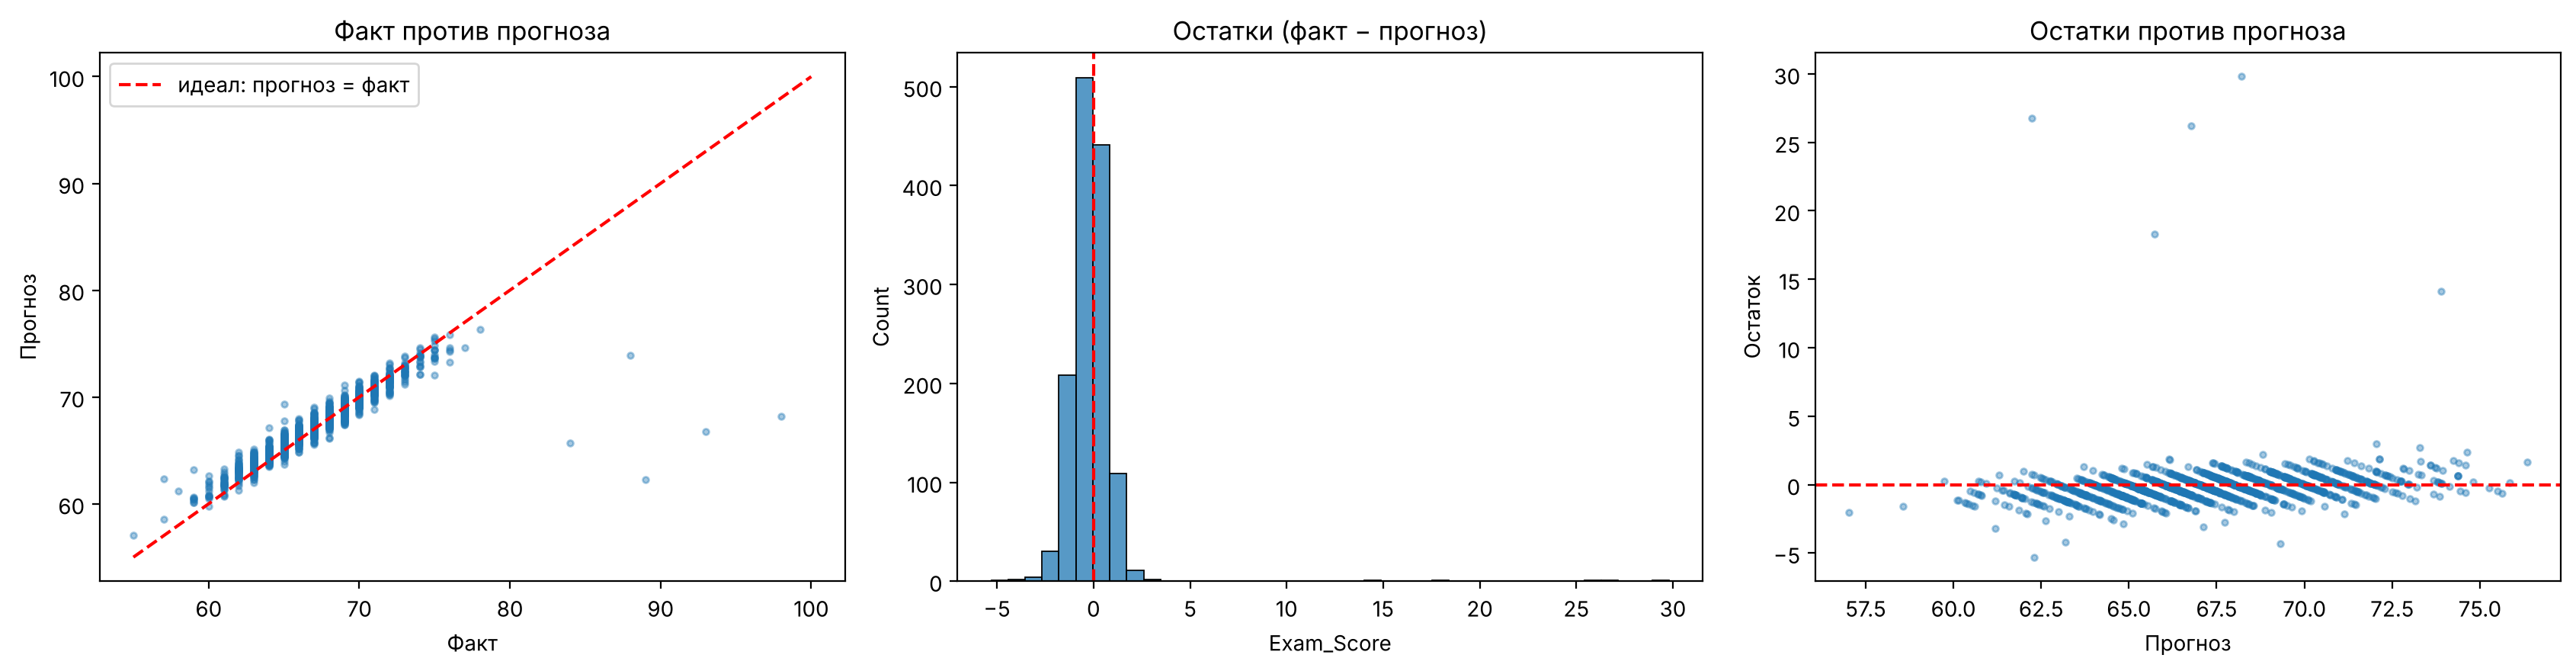

In [14]:
residuals = y_test - y_pred_base                       # остатки: факт минус прогноз
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(y_test, y_pred_base, s=8, alpha=0.4)   # каждая точка - один студент
axes[0].plot([55, 100], [55, 100], 'r--', label='идеал: прогноз = факт')
axes[0].set_xlabel('Факт'); axes[0].set_ylabel('Прогноз'); axes[0].set_title('Факт против прогноза'); axes[0].legend()

sns.histplot(residuals, bins=40, ax=axes[1])           # распределение ошибок
axes[1].axvline(0, color='r', ls='--'); axes[1].set_title('Остатки (факт − прогноз)')

axes[2].scatter(y_pred_base, residuals, s=8, alpha=0.4)  # остатки против прогноза
axes[2].axhline(0, color='r', ls='--')
axes[2].set_xlabel('Прогноз'); axes[2].set_ylabel('Остаток'); axes[2].set_title('Остатки против прогноза')
plt.tight_layout(); plt.show()

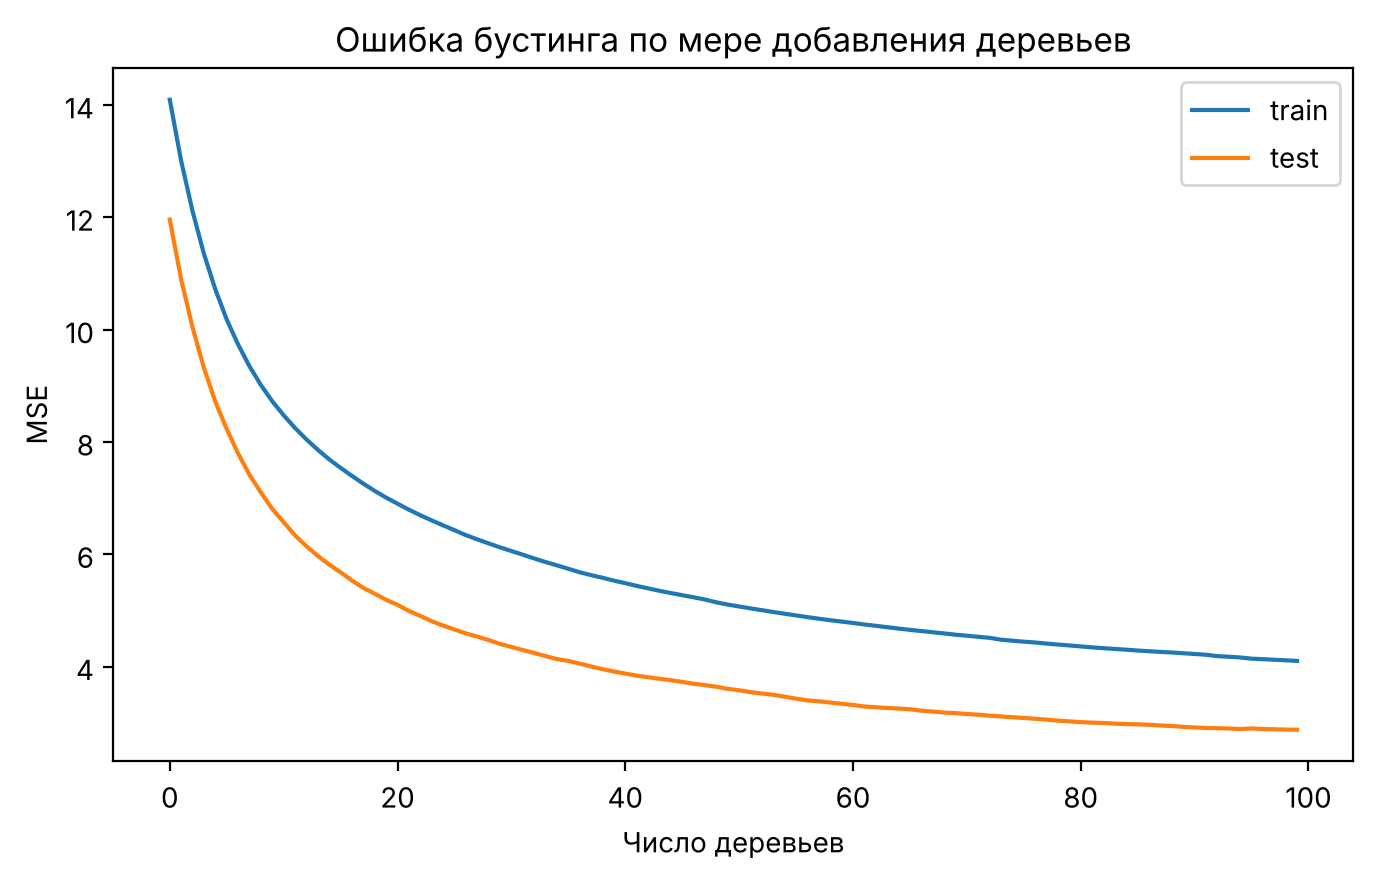

In [15]:
# кривая обучения: ошибка после каждого добавленного дерева (staged_predict)
train_curve = [mean_squared_error(y_train, p) for p in base_model.staged_predict(X_train)]
test_curve = [mean_squared_error(y_test, p) for p in base_model.staged_predict(X_test)]
plt.figure(figsize=(8, 4.5))
plt.plot(train_curve, label='train'); plt.plot(test_curve, label='test')
plt.xlabel('Число деревьев'); plt.ylabel('MSE'); plt.title('Ошибка бустинга по мере добавления деревьев'); plt.legend()
plt.show()

На графике «факт против прогноза» почти все точки лежат вдоль диагонали, но несколько студентов с очень высокими баллами (84–98) модель сильно недооценивает: остатки доходят до 30 баллов. Оценим, какую долю общей ошибки дают эти редкие случаи.

In [16]:
extreme = y_test >= 80                                 # редкие очень высокие баллы
def error_breakdown(y_true, y_pred):
    err = (y_true - y_pred) ** 2                        # квадраты ошибок
    typ = ~(y_true >= 80)                               # обычные студенты (балл < 80)
    return {'студентов с баллом >= 80': int((~typ).sum()),
            'доля их в сумме квадратов ошибок': err[~typ].sum() / err.sum(),
            'RMSE (балл < 80)': mean_squared_error(y_true[typ], y_pred[typ]) ** 0.5,
            'R² (балл < 80)': r2_score(y_true[typ], y_pred[typ])}
pd.Series(error_breakdown(y_test, y_pred_base)).round(4)

студентов с баллом >= 80            5.0000
доля их в сумме квадратов ошибок    0.7432
RMSE (балл < 80)                    0.8611
R² (балл < 80)                      0.9333
dtype: float64

**Выводы по заданию 4.**
- На графике «факт против прогноза» почти все точки лежат на диагонали, а остатки сосредоточены в пределах ±2 балла. Диагональные «полосы» возникают из-за того, что баллы целые.
- Несколько студентов (5 из 1322 в тесте) с фактическими баллами 84–98 получили прогнозы 62–74: модель их сильно недооценивает (остатки до 30 баллов). Эти пять человек дают около 74% всей суммы квадратов ошибок; без них RMSE равен 0.86, а R² = 0.93.
- Вывод: имеющиеся факторы хорошо объясняют результат обычных студентов, а исключительно высокие баллы по этим данным предсказать невозможно (их причины в таблице не отражены).
- Кривая обучения: ошибка и на train, и на test монотонно падает с добавлением деревьев. К 100 деревьям она ещё не вышла на плато, поэтому число деревьев по умолчанию (100) при скорости 0.1 для этой задачи немного мало. Это важно для следующих заданий.

### Задание 5
Провести настройку гиперпараметров (число деревьев, глубина деревьев и т. п.).

Сначала посмотрим, как каждый параметр по отдельности (остальные по умолчанию) влияет на качество. Качество оцениваем **кросс-валидацией на обучающей выборке** (5 частей, метрика R²), тестовую выборку не трогаем.

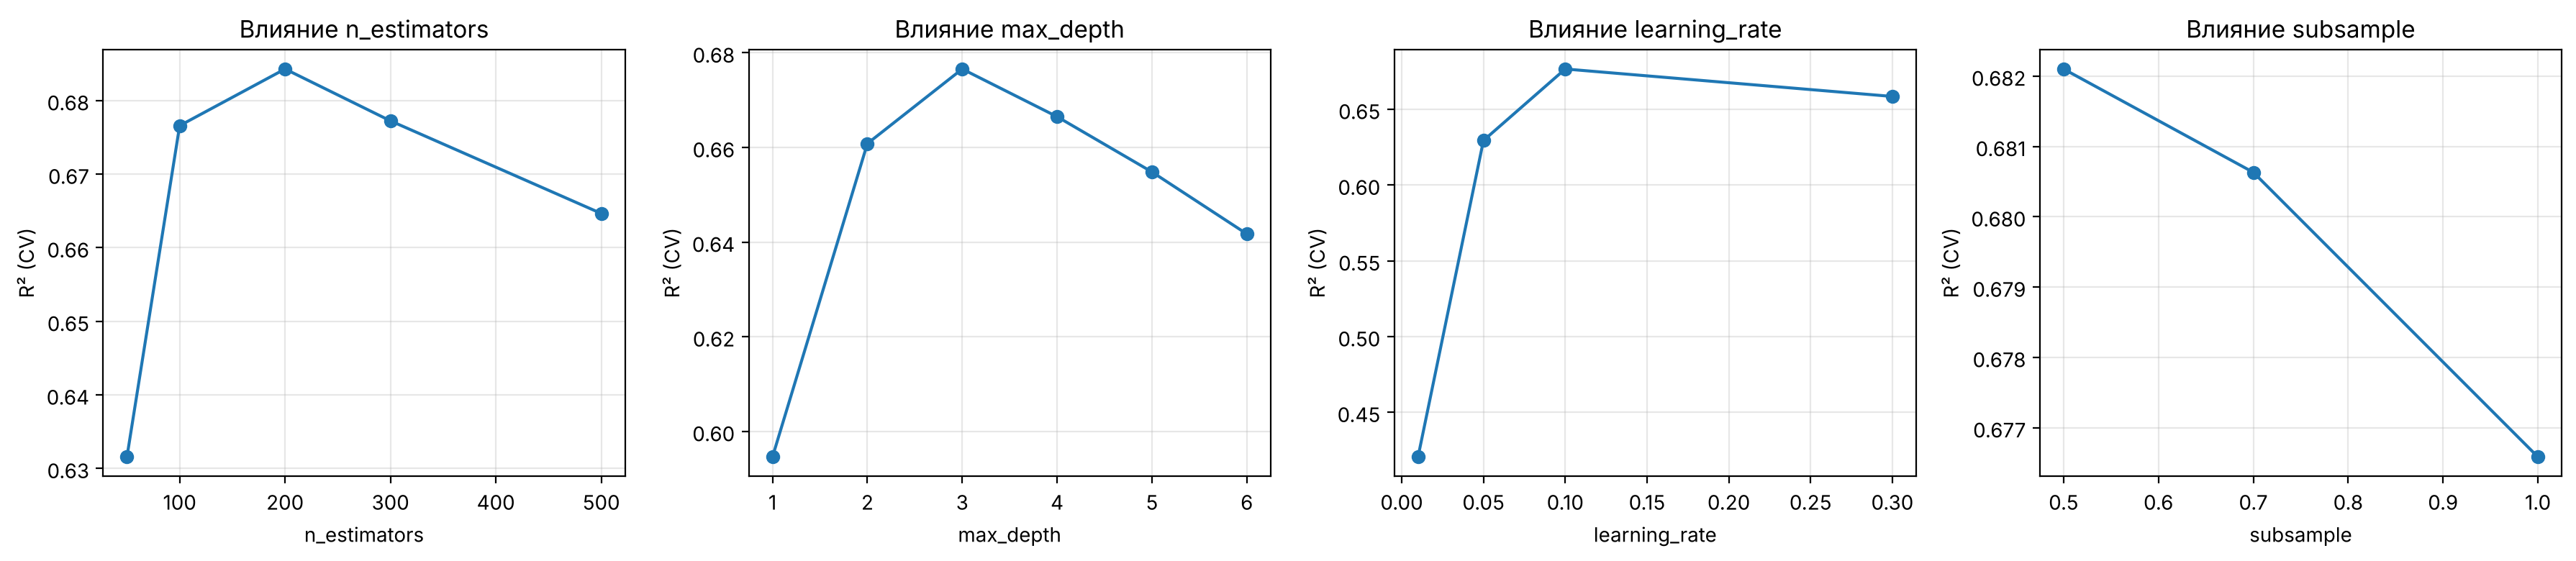

,параметр,значение,R² (CV)
0,n_estimators,50.00,0.6316
1,n_estimators,100.00,0.6766
2,n_estimators,200.00,0.6843
3,n_estimators,300.00,0.6772
4,n_estimators,500.00,0.6647
5,max_depth,1.00,0.5946
6,max_depth,2.00,0.6608
7,max_depth,3.00,0.6766
8,max_depth,4.00,0.6665
9,max_depth,5.00,0.6548


In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)    # схема кросс-валидации
sweeps = {
    'n_estimators': [50, 100, 200, 300, 500],         # число деревьев
    'max_depth': [1, 2, 3, 4, 5, 6],                   # глубина каждого дерева
    'learning_rate': [0.01, 0.05, 0.1, 0.3],           # скорость обучения
    'subsample': [0.5, 0.7, 1.0],                      # доля объектов для каждого дерева
}
sweep_scores = {}
for param, values in sweeps.items():
    sweep_scores[param] = [
        cross_val_score(GradientBoostingRegressor(random_state=RANDOM_STATE, **{param: v}),
                        X_train, y_train, cv=cv, scoring='r2', n_jobs=-1).mean()
        for v in values                                 # среднее R² по 5 частям для каждого значения
    ]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (param, values) in zip(axes, sweeps.items()):
    ax.plot(values, sweep_scores[param], marker='o')
    ax.set_xlabel(param); ax.set_ylabel('R² (CV)'); ax.set_title(f'Влияние {param}'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
pd.DataFrame([{'параметр': p, 'значение': v, 'R² (CV)': round(sc, 4)}
              for p, vals in sweeps.items() for v, sc in zip(vals, sweep_scores[p])])   # тот же результат в виде таблицы

**Выводы по заданию 5** (качество оценено кросс-валидацией, R²):
- **Число деревьев:** R² растёт от 0.632 (50 деревьев) до максимума 0.684 (200), затем падает (0.665 при 500): после 200 деревьев начинается переобучение.
- **Глубина деревьев:** слишком мелкие деревья недообучаются (глубина 1: 0.595), слишком глубокие переобучаются (глубина 6: 0.642); лучшая в этом одиночном замере — 3 (0.677); при совместном подборе в GridSearch (задание 6) лучшей окажется глубина 2.
- **Скорость обучения:** при 100 деревьях лучшая 0.1 (0.677). Очень малая 0.01 даёт 0.421, потому что 100 деревьев с таким мелким шагом ещё не успевают обучиться; слишком большая 0.3 уже хуже (0.659).
- **Подвыборка (`subsample`):** 0.5–0.7 слегка лучше, чем 1.0 (0.682 и 0.681 против 0.677): случайность при построении деревьев действует как регуляризация.
- **Параметры взаимосвязаны:** например, скорость 0.01 плоха лишь потому, что деревьев мало. Поэтому подбирать их нужно совместно, что мы и делаем в задании 6. Разброс R² между фолдами порядка 0.07, поэтому различия в третьем знаке (0.677 против 0.682) значимыми считать нельзя.

### Задание 6
Использовать `GridSearchCV` для подбора оптимальных параметров.

`GridSearchCV` перебирает все комбинации параметров из сетки, оценивает каждую кросс-валидацией и выбирает лучшую. Сетка: 3 × 2 × 3 × 2 = 36 комбинаций, умноженных на 5 частей CV, то есть 180 обучений.

In [18]:
param_grid = {
    'n_estimators': [100, 200, 300],                   # число деревьев
    'learning_rate': [0.03, 0.1],                      # скорость обучения
    'max_depth': [2, 3, 4],                            # глубина деревьев
    'subsample': [0.7, 1.0],                           # доля объектов на дерево
}
grid = GridSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE), param_grid,
                    cv=cv, scoring='r2', n_jobs=-1)    # перебор по сетке с кросс-валидацией
grid.fit(X_train, y_train)                              # обучение (перебор + итоговое переобучение)

print('Лучшие параметры:', grid.best_params_)
print('Лучший R² по кросс-валидации:', round(grid.best_score_, 4))

cv_table = pd.DataFrame(grid.cv_results_)[['param_n_estimators', 'param_learning_rate', 'param_max_depth',
                                           'param_subsample', 'mean_test_score', 'std_test_score']]
cv_table.sort_values('mean_test_score', ascending=False).head(10).round(4)   # 10 лучших комбинаций

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300, 'subsample': 1.0}
Лучший R² по кросс-валидации: 0.6983


,param_n_estimators,param_learning_rate,param_max_depth,param_subsample,mean_test_score,std_test_score
23,300,0.10,2,1.0,0.6983,0.0711
20,200,0.10,2,0.7,0.6972,0.0714
22,300,0.10,2,0.7,0.6970,0.0687
21,200,0.10,2,1.0,0.6934,0.0711
27,200,0.10,3,1.0,0.6843,0.0669
26,200,0.10,3,0.7,0.6837,0.0668
24,100,0.10,3,0.7,0.6806,0.0683
10,300,0.03,3,0.7,0.6804,0.0691
16,300,0.03,4,0.7,0.6793,0.0681
29,300,0.10,3,1.0,0.6772,0.0628


**Выводы по заданию 6.**
- Лучшая комбинация: `learning_rate=0.1`, `max_depth=2`, `n_estimators=300`, `subsample=1.0`; R² по кросс-валидации 0.698 (у модели по умолчанию 0.677).
- Первые четыре строки таблицы практически неразличимы (R² 0.693–0.698, при разбросе по фолдам около 0.07): все они используют скорость 0.1 и неглубокие деревья (глубина 2), но 200–300 штук. Побеждает вариант с максимальным средним.
- Общая картина: для этих данных лучше **много неглубоких деревьев**: каждое дерево глубиной 2 учитывает не более двух признаков в цепочке, и сложные взаимодействия модель накапливает суммой деревьев, а не глубиной одного.

### Задание 7
Повторить обучение и оценку с новыми параметрами.

In [19]:
tuned_model = GradientBoostingRegressor(random_state=RANDOM_STATE, **grid.best_params_)  # модель с лучшими параметрами
tuned_model.fit(X_train, y_train)                       # обучение на train
y_pred_tuned = tuned_model.predict(X_test)              # прогнозы на test

comparison = pd.DataFrame({
    'По умолчанию, train': regression_metrics(y_train, base_model.predict(X_train)),
    'По умолчанию, test': regression_metrics(y_test, y_pred_base),
    'Подобранные, train': regression_metrics(y_train, tuned_model.predict(X_train)),
    'Подобранные, test': regression_metrics(y_test, y_pred_tuned),
}).T.round(4)
comparison

,MSE,RMSE,MAE,R2
"По умолчанию, train",4.1014,2.0252,0.7560,0.7336
"По умолчанию, test",2.8762,1.6959,0.7497,0.7825
"Подобранные, train",4.0750,2.0187,0.6175,0.7353
"Подобранные, test",2.5470,1.5959,0.5818,0.8074


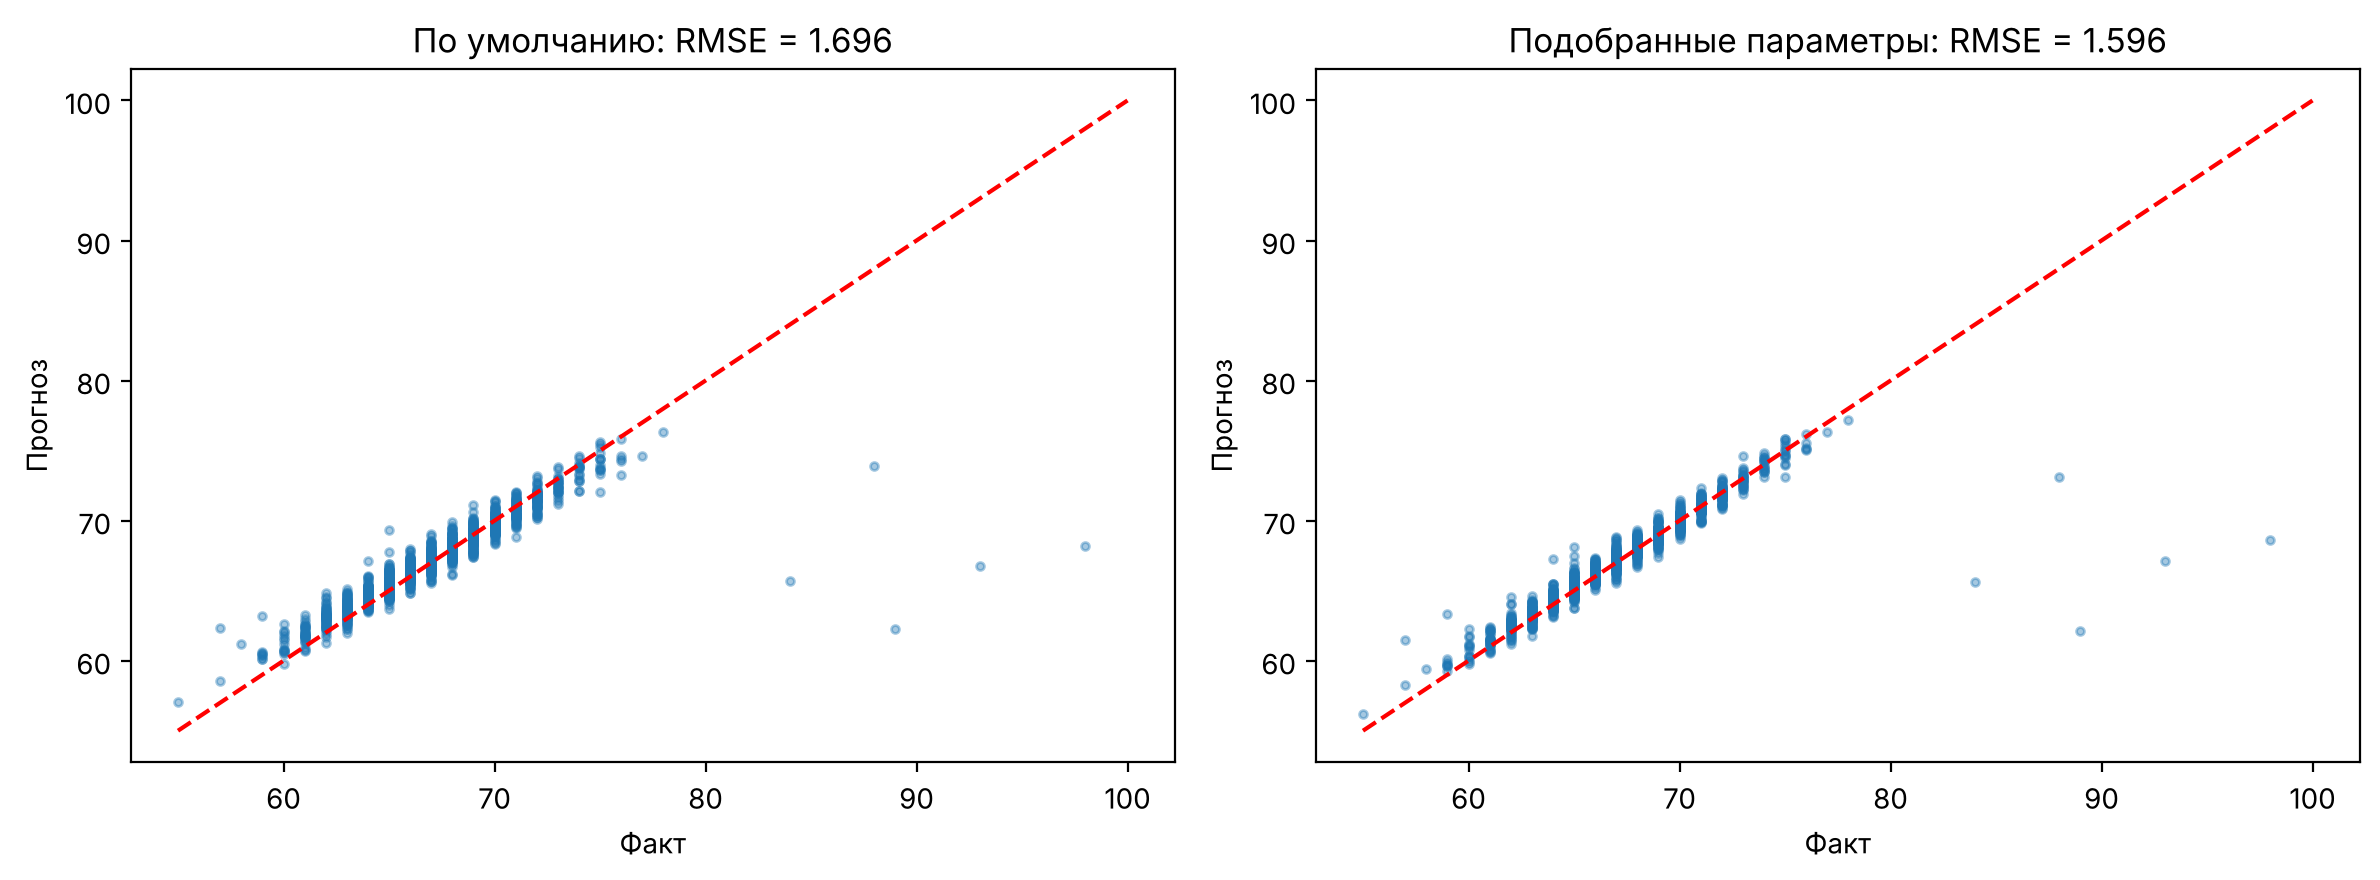

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, title in zip(axes, [y_pred_base, y_pred_tuned], ['По умолчанию', 'Подобранные параметры']):
    ax.scatter(y_test, pred, s=8, alpha=0.4)            # факт против прогноза
    ax.plot([55, 100], [55, 100], 'r--')
    ax.set_xlabel('Факт'); ax.set_ylabel('Прогноз')
    ax.set_title(f"{title}: RMSE = {mean_squared_error(y_test, pred) ** 0.5:.3f}")
plt.tight_layout(); plt.show()

In [21]:
pd.DataFrame({'По умолчанию': error_breakdown(y_test, y_pred_base),
              'Подобранные': error_breakdown(y_test, y_pred_tuned)}).round(4)   # разбор ошибки: обычные студенты и редкие высокие баллы

,По умолчанию,Подобранные
студентов с баллом >= 80,5.0000,5.0000
доля их в сумме квадратов ошибок,0.7432,0.8359
RMSE (балл < 80),0.8611,0.6477
R² (балл < 80),0.9333,0.9623


**Выводы по заданию 7.**
- Подобранные параметры улучшили все метрики на тесте: RMSE 1.696 → 1.596, MAE 0.750 → 0.582 (на 22% меньше), R² 0.783 → 0.807.
- На обучающей выборке R² почти не изменился (0.734 → 0.735): модель не стала сильнее подгоняться под train, то есть улучшение не за счёт переобучения.
- Таблица разбора ошибок показывает, где именно выигрыш: для 99.6% обычных студентов (балл < 80) RMSE упал с 0.86 до 0.65, а R² вырос с 0.93 до 0.96. Общий RMSE улучшился скромнее (1.70 → 1.60), потому что в нём доминируют пять непредсказуемых студентов с очень высокими баллами (их доля в сумме квадратов ошибок — 74% → 84%; им настройка помочь не может).
- Для честности: прирост R² по кросс-валидации тоже небольшой (0.677 → 0.698), а оценка на тесте (0.807) выше кросс-валидационной (0.698), потому что в тесте случайно оказалось меньше экстремальных баллов. Поэтому абсолютные значения нужно сравнивать осторожно, а надёжный вывод такой: подбор параметров дал заметное улучшение на типичных студентах.

### Задание 8
Исследовать влияние скорости обучения (`learning_rate`) и количества деревьев на качество модели.

Записываем ошибку после каждого добавленного дерева (`staged_predict`), поэтому одним обучением на 500 деревьев получаем качество для любого числа деревьев от 1 до 500. Остальные параметры берём подобранные в задании 6. Чтобы не «подглядывать» в тест, оцениваем на **валидационной** части, выделенной из обучающей выборки.

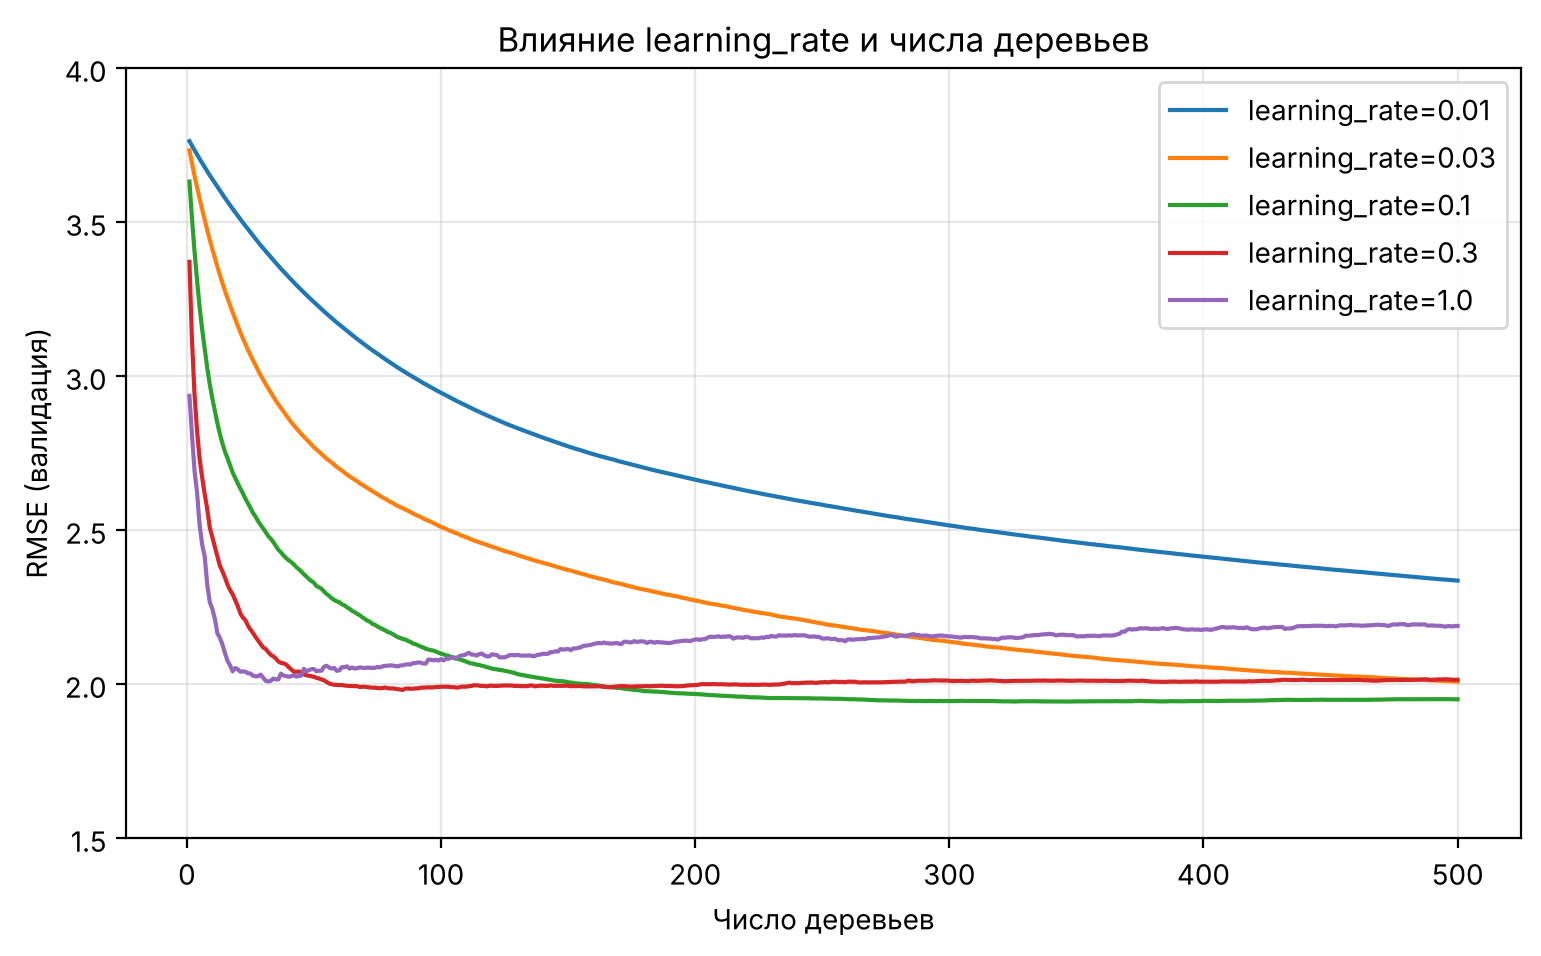

In [22]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)  # train -> fit + val
fixed = {k: v for k, v in grid.best_params_.items() if k not in ('learning_rate', 'n_estimators')}  # глубина и subsample из GridSearch
rates = [0.01, 0.03, 0.1, 0.3, 1.0]
N_MAX = 500
val_rmse = {}
for lr in rates:
    gb = GradientBoostingRegressor(learning_rate=lr, n_estimators=N_MAX, random_state=RANDOM_STATE, **fixed).fit(X_fit, y_fit)
    val_rmse[lr] = np.array([mean_squared_error(y_val, p) ** 0.5 for p in gb.staged_predict(X_val)])  # RMSE после каждого дерева

plt.figure(figsize=(9, 5))
for lr, curve in val_rmse.items():
    plt.plot(range(1, N_MAX + 1), curve, label=f'learning_rate={lr}')
plt.xlabel('Число деревьев'); plt.ylabel('RMSE (валидация)'); plt.ylim(1.5, 4)
plt.title('Влияние learning_rate и числа деревьев'); plt.legend(); plt.grid(alpha=0.3); plt.show()

learning_rate,0.01,0.03,0.10,0.30,1.00
деревьев,,,,,
10,3.640,3.413,2.929,2.477,2.245
50,3.241,2.770,2.329,2.024,2.049
100,2.946,2.511,2.099,1.992,2.082
200,2.664,2.272,1.969,1.998,2.145
300,2.516,2.138,1.945,2.011,2.155
500,2.336,2.009,1.951,2.015,2.189


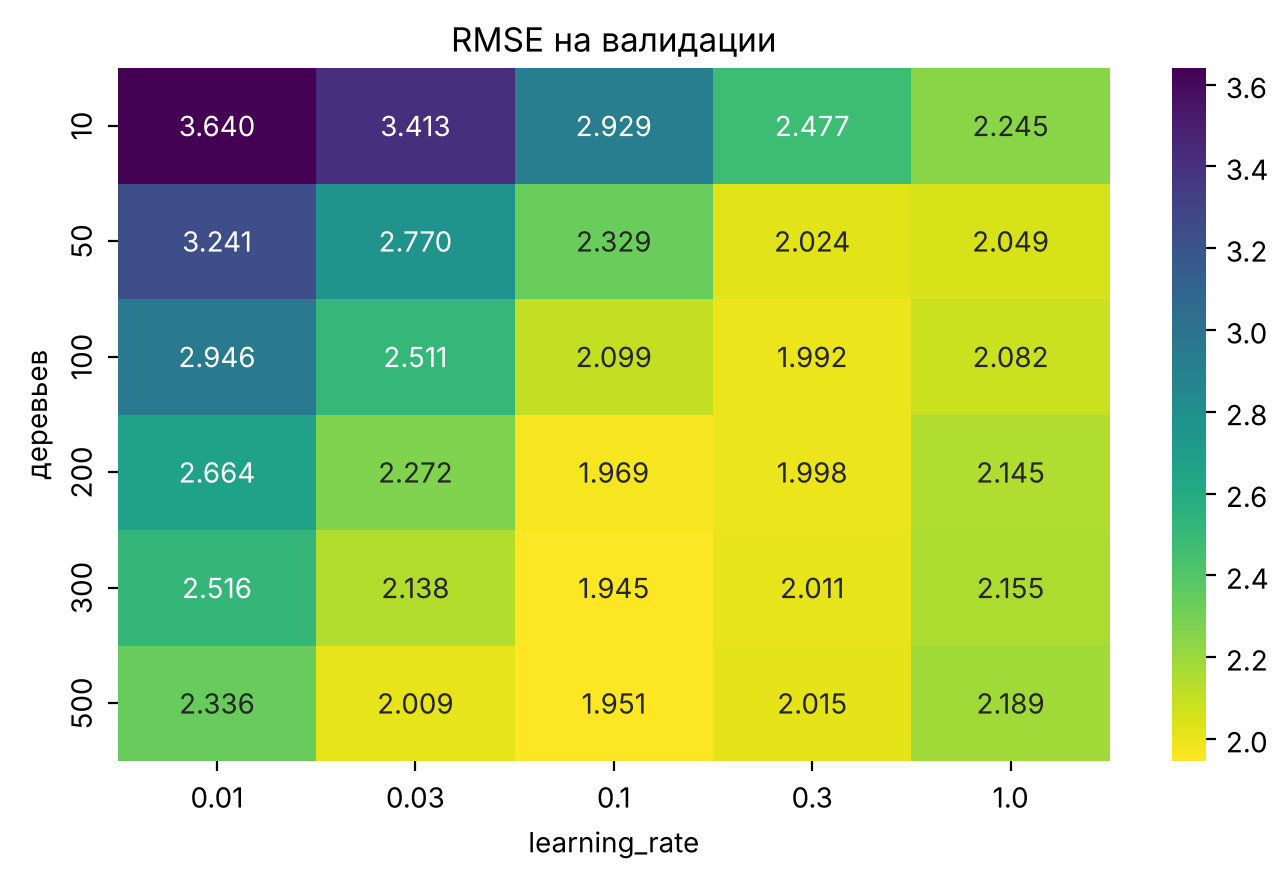

,лучшее число деревьев,мин. RMSE
learning_rate,,
0.01,500,2.3364
0.03,500,2.0087
0.10,341,1.9437
0.30,85,1.9815
1.00,32,2.0090


In [23]:
counts = [10, 50, 100, 200, 300, 500]
table = pd.DataFrame({lr: [val_rmse[lr][n - 1] for n in counts] for lr in rates}, index=counts)
table.index.name = 'деревьев'; table.columns.name = 'learning_rate'
display(table.round(3))                                 # те же значения в виде таблицы

plt.figure(figsize=(8, 4.5))
sns.heatmap(table, annot=True, fmt='.3f', cmap='viridis_r')   # чем светлее, тем меньше ошибка (лучше)
plt.title('RMSE на валидации'); plt.show()

best = pd.DataFrame({'лучшее число деревьев': [int(val_rmse[lr].argmin()) + 1 for lr in rates],
                     'мин. RMSE': [val_rmse[lr].min() for lr in rates]}, index=rates).round(4)
best.index.name = 'learning_rate'; best

**Выводы по заданию 8** (RMSE на валидации; сравнивать нужно между собой, а не с тестом, так как это другая выборка):

| learning_rate | Лучшее число деревьев | Мин. RMSE | Что происходит |
|---|---|---|---|
| 0.01 | 500 и больше | 2.336 | не успел обучиться: ошибка ещё падает на 500 деревьях |
| 0.03 | 500 и больше | 2.009 | ещё падает на 500 деревьях |
| 0.1 | 341 | **1.944** | плавный спуск и плато с 200 деревьев |
| 0.3 | 85 | 1.982 | минимум рано, затем небольшой рост (2.015 на 500) |
| 1.0 | 32 | 2.009 | быстро переобучается: с 32 до 500 деревьев ошибка растёт до 2.189 |

- **Компромисс скорость и число деревьев.** Чем меньше шаг, тем больше деревьев нужно (при 0.01 их нужны тысячи), а чем больше шаг, тем меньше, но тем быстрее модель переобучается и тем более «дёрганой» становится кривая.
- **У каждой скорости своё оптимальное число деревьев.** Дальше него ошибка на валидации перестаёт падать (при малых шагах) или растёт (при больших).
- **Лучший результат даёт умеренный шаг 0.1 с 200–350 деревьями**, что совпадает с выбором GridSearchCV (0.1 и 300 деревьев). Меньший шаг при достаточно большом числе деревьев мог бы дать то же или чуть лучшее качество, но потребовал бы больше вычислений.
- **Практическое правило:** задавать небольшую скорость обучения и подбирать число деревьев по ошибке на валидации (в sklearn для этого есть ранняя остановка `n_iter_no_change`).

## Общий вывод

Градиентный бустинг (`GradientBoostingRegressor`) предсказывает экзаменационный балл студента по 19 факторам. Модель по умолчанию объясняет 78% разброса баллов (RMSE 1.70 балла на тесте), после подбора гиперпараметров через `GridSearchCV` (скорость 0.1, глубина 2, 300 деревьев) качество выросло до R² = 0.81 и RMSE 1.60; для обычных студентов ошибка составляет около 0.65 балла.

Основные наблюдения: (1) число и глубина деревьев работают по принципу «золотой середины» (мало — недообучение, много — переобучение); (2) скорость обучения и число деревьев нужно подбирать вместе: чем меньше шаг, тем больше деревьев; (3) для этих данных лучше много неглубоких деревьев; (4) общие метрики в этой задаче определяются несколькими студентами с исключительно высокими баллами, которых модель предсказать не может, поэтому для честной оценки полезно смотреть ещё и MAE и ошибку на обычных студентах.